# NN_L4_transfer_curves

**EuroSAT: validation accuracy of a CNN from scratch and of a fine-tuned ResNet-18, frozen ResNet-18 + logistic regression, and test accuracy against the label budget.**

Neural Networks and Deep Learning (NN), Lecture 4 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L4/NN_L4_transfer_curves/NN_L4_transfer_curves.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Transfer learning: from scratch vs frozen features vs fine-tuning, and what happens with few labels.

scratch, test accuracy (%) = 97.78   [eurosat.scratch_acc]
fine-tuned, test accuracy (%) = 98.76   [eurosat.finetune_acc]
frozen + logistic, test accuracy (%) = 93.48   [eurosat.probe_acc]
scratch, 10 tiles/class (%) = 69.9   [budget.scratch.10]
finetune, 10 tiles/class (%) = 87.8   [budget.finetune.10]
probe, 10 tiles/class (%) = 78.6   [budget.probe.10]


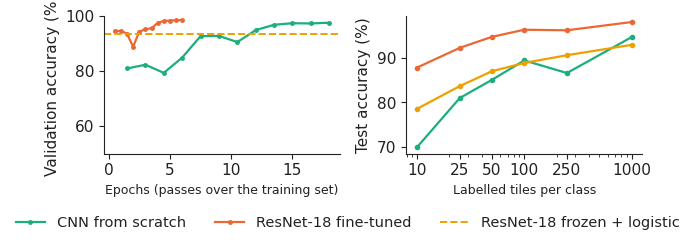

In [3]:
import json, urllib.request
_F = 'transfer_curves_results.json'
R = json.load(open(_F)) if os.path.isfile(_F) else json.load(urllib.request.urlopen(REPO + 'Quantlets/L4/NN_L4_transfer_curves/' + _F))
show('eurosat.scratch_acc', 'scratch, test accuracy (%)', round(100 * R['scratch_test'], 2)); show('eurosat.finetune_acc', 'fine-tuned, test accuracy (%)', round(100 * R['finetune_test'], 2))
show('eurosat.probe_acc', 'frozen + logistic, test accuracy (%)', round(100 * R['probe_test'], 2))
B = R['budget']; n = [10, 25, 50, 100, 250, 1000]
for k in ['scratch', 'finetune', 'probe']:
    show(f'budget.{k}.10', f'{k}, 10 tiles/class (%)', round(100 * float(np.mean(B[k]['10'])), 1))
fig, axes = plt.subplots(1, 2, figsize=(6.4, 2.5))
for k, c, l in [('scratch', PAL['benchmark'], 'CNN from scratch'), ('finetune', PAL['model'], 'ResNet-18 fine-tuned')]:
    h = np.array(R[k + '_hist']); axes[0].plot(h[:, 0], 100 * h[:, 1], color=c, lw=1.6, marker='o', ms=2.5, label=l)
axes[0].axhline(100 * R['probe_valid'], color=PAL['alt'], lw=1.4, ls='--', label='ResNet-18 frozen + logistic')
axes[0].set_xlabel('Epochs (passes over the training set)', fontsize=9); axes[0].set_ylabel('Validation accuracy (%)'); axes[0].set_ylim(50, 100)
for k, c in [('scratch', PAL['benchmark']), ('finetune', PAL['model']), ('probe', PAL['alt'])]:
    axes[1].plot(n, [100 * np.mean(B[k][str(x)]) for x in n], color=c, lw=1.6, marker='o', ms=3)
axes[1].set_xscale('log'); axes[1].set_xticks(n); axes[1].set_xticklabels([str(x) for x in n])
axes[1].set_xlabel('Labelled tiles per class', fontsize=9); axes[1].set_ylabel('Test accuracy (%)')
legend_bottom(fig, ncol=3)
fig.tight_layout(rect=(0, 0.12, 1, 1))
fig.savefig('transfer_curves.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()